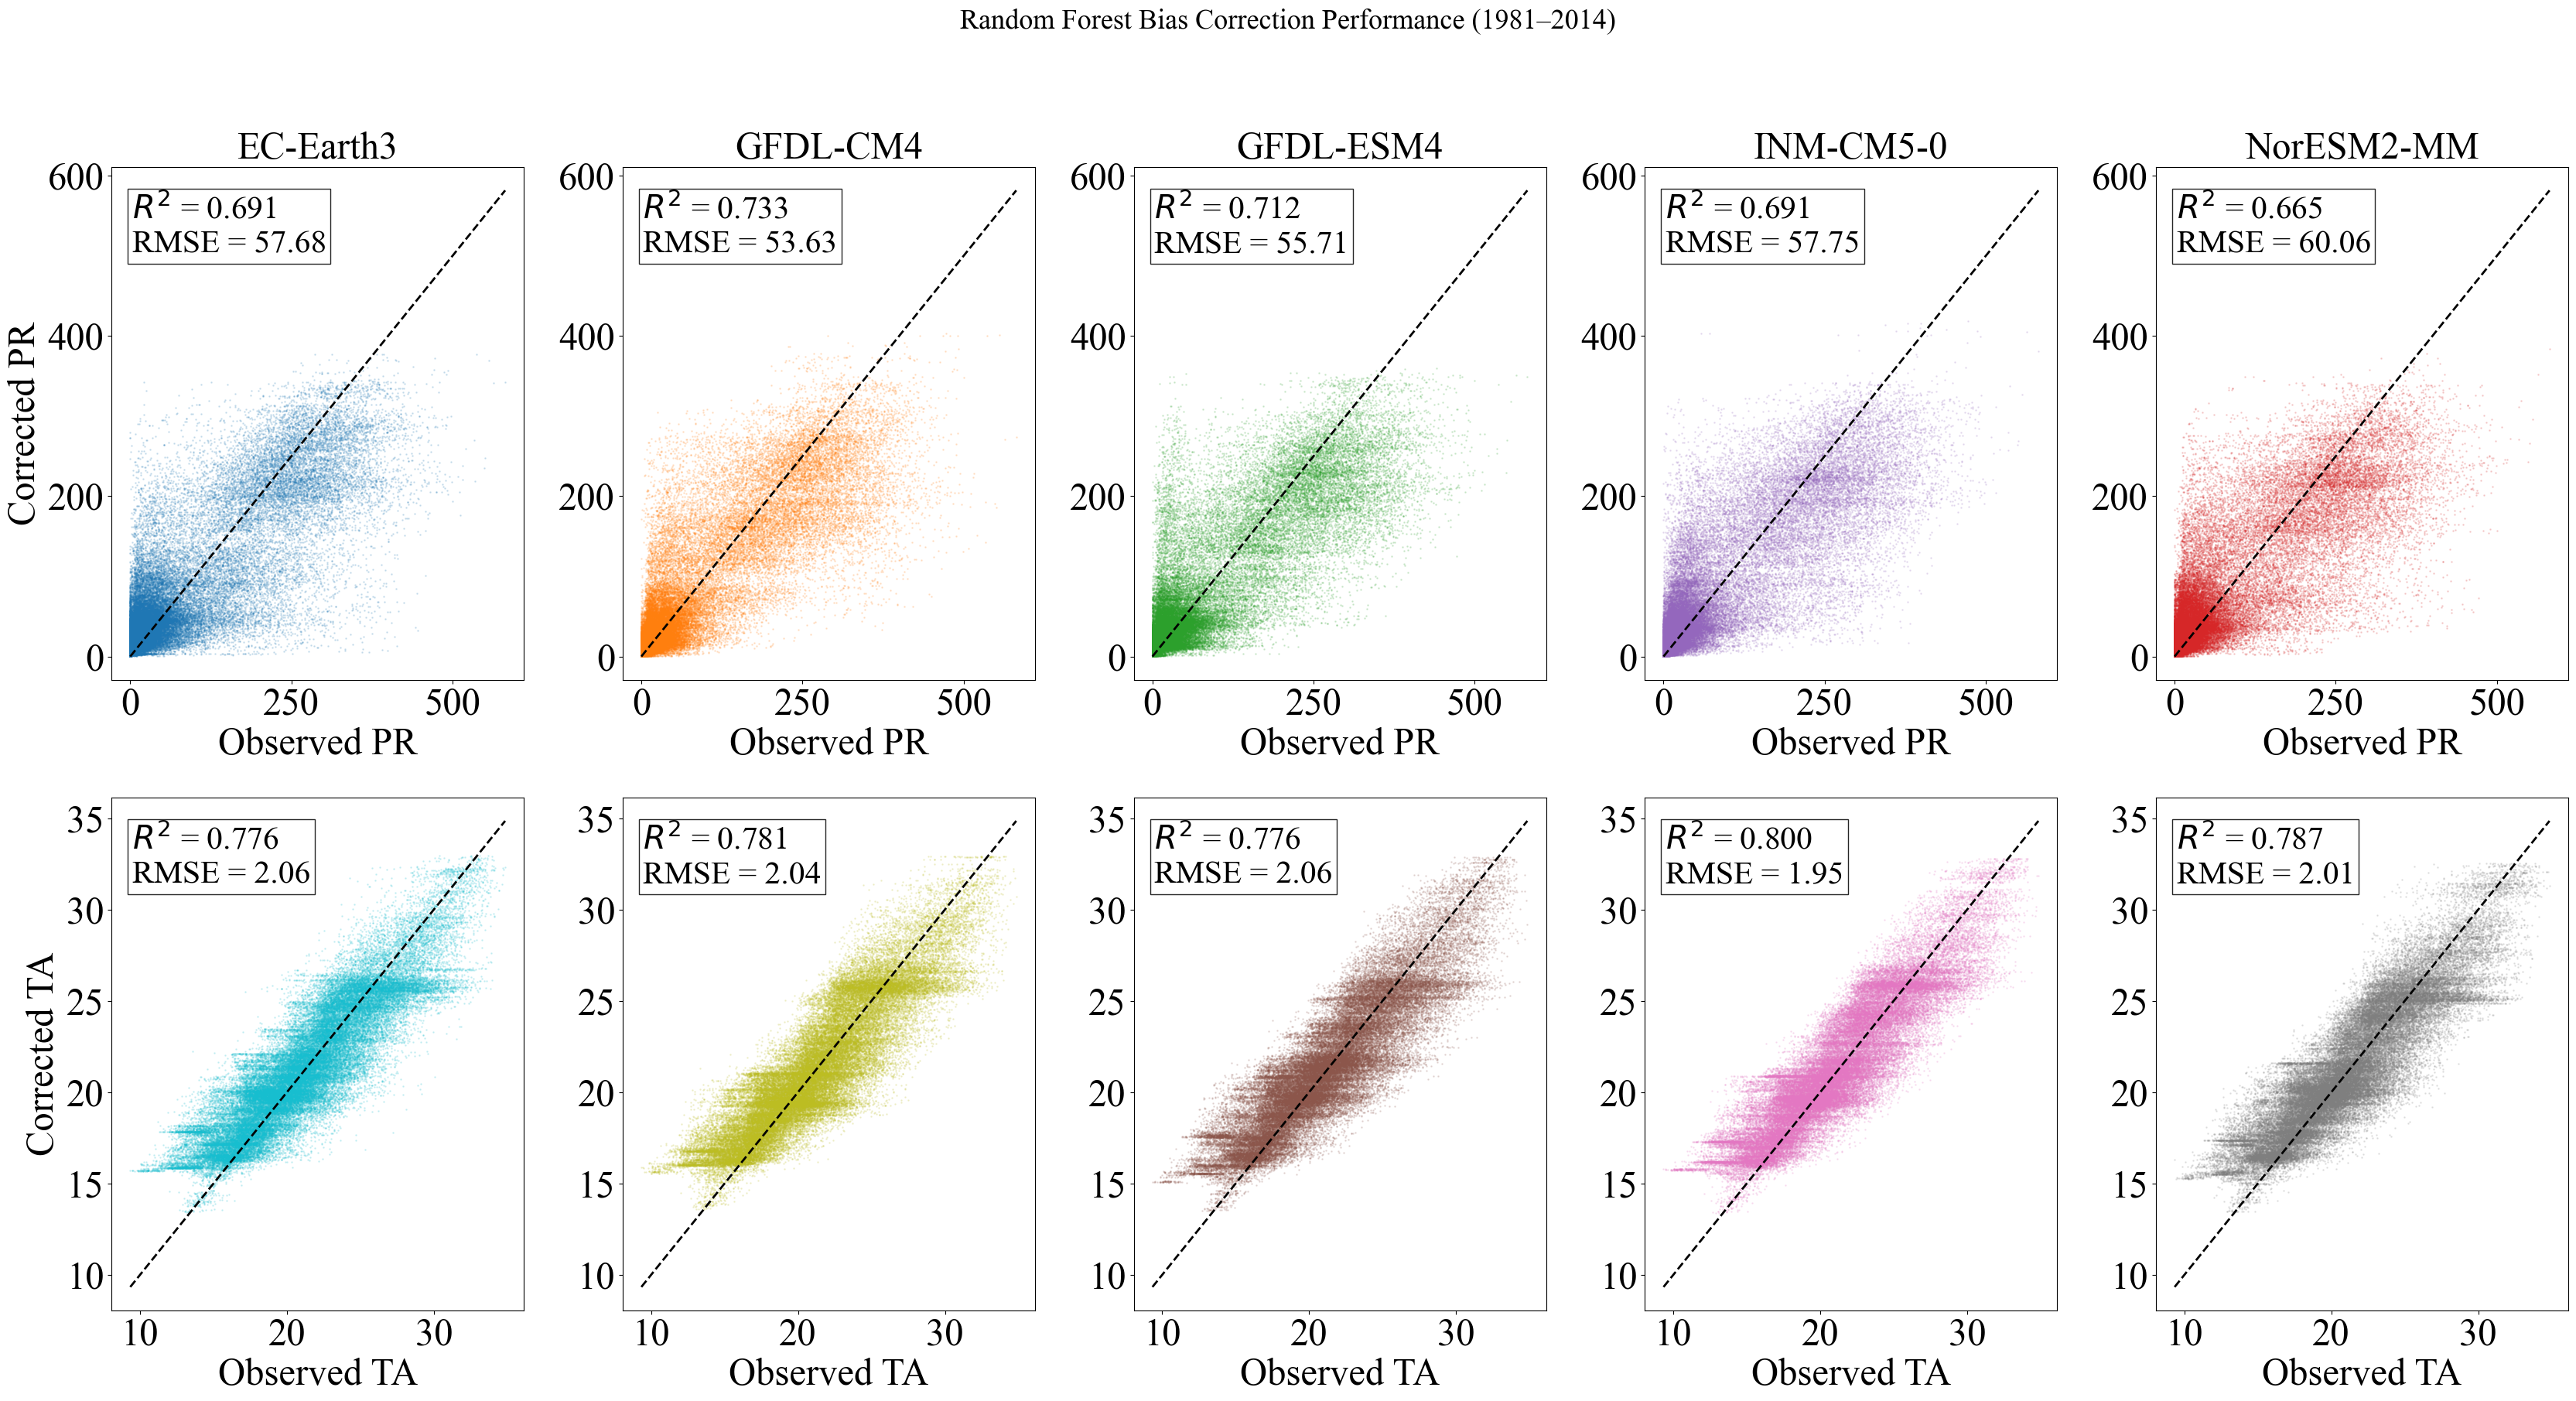

Saved:
C:\Users\gerii\Documents\projects\tekeze\RF_bias_correction_scatter_1981_2014.png


In [10]:
import os
import glob
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_squared_error

# ============================================================
# PATHS
# ============================================================

base = r"C:\Users\gerii\Documents\projects\tekeze"

obs_pr = os.path.join(base, "CHIRPS_resampled")
obs_ta = os.path.join(base, "ERA5_resampled")

corr_base = os.path.join(base, "NEX-GDDP-CMIP6")

models = [
    "EC-Earth3",
    "GFDL-CM4",
    "GFDL-ESM4",
    "INM-CM5-0",
    "NorESM2-MM"
]

start_year = 1981
end_year = 2014

output_png = os.path.join(
    base,
    "RF_bias_correction_scatter_1981_2014.png"
)

# ============================================================
# SETTINGS
# ============================================================

plt.rcParams.update({
    "font.size": 30,
    "axes.titlesize": 35,
    "axes.labelsize": 35,
    "xtick.labelsize": 35,
    "ytick.labelsize": 35,
    "legend.fontsize": 35
})

colors_pr = [
    "#1f77b4",
    "#ff7f0e",
    "#2ca02c",
    "#9467bd",
    "#d62728"
]

colors_ta = [
    "#17becf",
    "#bcbd22",
    "#8c564b",
    "#e377c2",
    "#7f7f7f"
]

# ============================================================
# FUNCTION
# ============================================================

def load_common_pixels(obs_folder, corr_folder):

    obs_all = []
    corr_all = []

    for year in range(start_year, end_year + 1):

        for month in range(1, 13):

            fname = f"{year}_{month:02d}.tif"

            obs_file = os.path.join(obs_folder, fname)
            corr_file = os.path.join(corr_folder, fname)

            if not (
                os.path.exists(obs_file)
                and os.path.exists(corr_file)
            ):
                continue

            try:

                with rasterio.open(obs_file) as src:

                    obs = src.read(1).astype(np.float32)
                    nodata_obs = src.nodata

                with rasterio.open(corr_file) as src:

                    corr = src.read(1).astype(np.float32)
                    nodata_corr = src.nodata

                mask = np.isfinite(obs) & np.isfinite(corr)

                if nodata_obs is not None:
                    mask &= (obs != nodata_obs)

                if nodata_corr is not None:
                    mask &= (corr != nodata_corr)

                mask &= (obs > -9990)
                mask &= (corr > -9990)

                obs_all.append(obs[mask].ravel())
                corr_all.append(corr[mask].ravel())

            except Exception as e:
                print(f"Skipped {fname}: {e}")

    obs_all = np.concatenate(obs_all)
    corr_all = np.concatenate(corr_all)

    return obs_all, corr_all


# ============================================================
# FIGURE
# ============================================================

fig, axes = plt.subplots(
    2,
    5,
    figsize=(34, 18)
)

# ============================================================
# PRECIPITATION
# ============================================================

for i, model in enumerate(models):

    ax = axes[0, i]

    corr = os.path.join(
        corr_base,
        "pr_corrected_RF",
        model,
        "historical"
    )

    obs, pred = load_common_pixels(
        obs_pr,
        corr
    )

    r2 = r2_score(obs, pred)
    rmse = np.sqrt(
        mean_squared_error(obs, pred)
    )

    # subsample if huge
    if len(obs) > 300000:
        idx = np.random.choice(
            len(obs),
            300000,
            replace=False
        )
        obs = obs[idx]
        pred = pred[idx]

    ax.scatter(
        obs,
        pred,
        s=1,
        alpha=0.15,
        color=colors_pr[i]
    )

    mn = min(obs.min(), pred.min())
    mx = max(obs.max(), pred.max())

    ax.plot(
        [mn, mx],
        [mn, mx],
        "k--",
        lw=2
    )

    ax.text(
        0.05,
        0.95,
        f"$R^2$ = {r2:.3f}\nRMSE = {rmse:.2f}",
        transform=ax.transAxes,
        va="top",
        bbox=dict(
            facecolor="white",
            alpha=0.85
        )
    )

    ax.set_title(model)

    if i == 0:
        ax.set_ylabel(
            "Corrected PR"
        )

    ax.set_xlabel(
        "Observed PR"
    )

# ============================================================
# TEMPERATURE
# ============================================================

for i, model in enumerate(models):

    ax = axes[1, i]

    corr = os.path.join(
        corr_base,
        "ta_corrected_RF",
        model,
        "historical"
    )

    obs, pred = load_common_pixels(
        obs_ta,
        corr
    )

    r2 = r2_score(obs, pred)

    rmse = np.sqrt(
        mean_squared_error(
            obs,
            pred
        )
    )

    if len(obs) > 300000:

        idx = np.random.choice(
            len(obs),
            300000,
            replace=False
        )

        obs = obs[idx]
        pred = pred[idx]

    ax.scatter(
        obs,
        pred,
        s=1,
        alpha=0.15,
        color=colors_ta[i]
    )

    mn = min(obs.min(), pred.min())
    mx = max(obs.max(), pred.max())

    ax.plot(
        [mn, mx],
        [mn, mx],
        "k--",
        lw=2
    )

    ax.text(
        0.05,
        0.95,
        f"$R^2$ = {r2:.3f}\nRMSE = {rmse:.2f}",
        transform=ax.transAxes,
        va="top",
        bbox=dict(
            facecolor="white",
            alpha=0.85
        )
    )

    if i == 0:
        ax.set_ylabel(
            "Corrected TA"
        )

    ax.set_xlabel(
        "Observed TA"
    )

# ============================================================
# FINALIZE
# ============================================================

fig.suptitle(
    "Random Forest Bias Correction Performance (1981–2014)",
    fontsize=26,
    y=1.02
)

plt.tight_layout()

plt.savefig(
    output_png,
    dpi=450,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(output_png)

### pragraph for result and discussion section

In [12]:
# ============================================================
# GENERATE RESULT & DISCUSSION PARAGRAPHS
# ============================================================

output_txt = os.path.join(
    base,
    "RF_result_discussion.txt"
)

paragraphs = []


def get_statistics(
        obs_folder,
        corr_folder
):

    obs_all = []
    pred_all = []

    pixel_count = []
    months = 0

    for year in range(
        start_year,
        end_year + 1
    ):

        for month in range(
            1,
            13
        ):

            fname = (
                f"{year}_{month:02d}.tif"
            )

            obs_file = os.path.join(
                obs_folder,
                fname
            )

            corr_file = os.path.join(
                corr_folder,
                fname
            )

            if not (
                os.path.exists(obs_file)
                and
                os.path.exists(corr_file)
            ):
                continue

            try:

                with rasterio.open(
                        obs_file
                ) as src:

                    obs = (
                        src.read(1)
                        .astype(
                            np.float32
                        )
                    )

                    nodata_obs = (
                        src.nodata
                    )

                with rasterio.open(
                        corr_file
                ) as src:

                    pred = (
                        src.read(1)
                        .astype(
                            np.float32
                        )
                    )

                    nodata_corr = (
                        src.nodata
                    )

                mask = (
                    np.isfinite(obs)
                    &
                    np.isfinite(pred)
                )

                if nodata_obs is not None:
                    mask &= (
                        obs
                        !=
                        nodata_obs
                    )

                if nodata_corr is not None:
                    mask &= (
                        pred
                        !=
                        nodata_corr
                    )

                mask &= (
                    obs > -9990
                )

                mask &= (
                    pred > -9990
                )

                pixel_count.append(
                    mask.sum()
                )

                months += 1

                obs_all.append(
                    obs[mask]
                )

                pred_all.append(
                    pred[mask]
                )

            except:
                pass

    obs_all = np.concatenate(
        obs_all
    )

    pred_all = np.concatenate(
        pred_all
    )

    r2 = r2_score(
        obs_all,
        pred_all
    )

    rmse = np.sqrt(
        mean_squared_error(
            obs_all,
            pred_all
        )
    )

    return (

        r2,

        rmse,

        int(
            np.mean(
                pixel_count
            )
        ),

        len(
            obs_all
        )

    )


for variable in [

    "pr",
    "ta"

]:

    for model in models:

        folder = os.path.join(

            corr_base,

            f"{variable}_corrected_RF",

            model,

            "historical"

        )

        if variable == "pr":

            obs_folder = obs_pr
            name = "precipitation"
            unit = "mm month⁻¹"

        else:

            obs_folder = obs_ta
            name = "air temperature"
            unit = "°C"

        r2, rmse, pix, sample = (
            get_statistics(
                obs_folder,
                folder
            )
        )

        para = (

f"For {model}, the Random Forest bias correction reproduced observed "
f"{name} with an R² of {r2:.3f} and an RMSE of {rmse:.2f} {unit}. "
f"The evaluation was based on pixel-wise comparison using an average "
f"of {pix} valid 0.25° grid cells per month across the basin during "
f"1981–2014, resulting in {sample:,} paired observations. Compared with "
f"basin-average assessment, the pixel-level evaluation captures local "
f"spatial variability and residual disagreement more explicitly; therefore, "
f"a slightly lower R² is expected while providing a more robust estimate "
f"of correction performance."

        )

        paragraphs.append(
            para
        )

        print("\n")
        print(para)
        print()


with open(
    output_txt,
    "w",
    encoding="utf-8"
) as f:

    for p in paragraphs:

        f.write(
            p
            +
            "\n\n"
        )

print(
    "\nParagraph file saved:"
)

print(
    output_txt
)




For EC-Earth3, the Random Forest bias correction reproduced observed precipitation with an R² of 0.691 and an RMSE of 57.68 mm month⁻¹. The evaluation was based on pixel-wise comparison using an average of 146 valid 0.25° grid cells per month across the basin during 1981–2014, resulting in 59,568 paired observations. Compared with basin-average assessment, the pixel-level evaluation captures local spatial variability and residual disagreement more explicitly; therefore, a slightly lower R² is expected while providing a more robust estimate of correction performance.



For GFDL-CM4, the Random Forest bias correction reproduced observed precipitation with an R² of 0.733 and an RMSE of 53.63 mm month⁻¹. The evaluation was based on pixel-wise comparison using an average of 146 valid 0.25° grid cells per month across the basin during 1981–2014, resulting in 59,568 paired observations. Compared with basin-average assessment, the pixel-level evaluation captures local spatial variability an